# Training: EfficientNetB0 and ResNet50

Two pretrained models (ImageNet), trained on the crops from the first notebook.

In [17]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, f1_score

tf.random.set_seed(42)
np.random.seed(42)
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## Load the data

In [18]:
for dirname, folders, files in os.walk('/kaggle/input'):
    if 'train' in folders:
        print(dirname)

/kaggle/input/datasets/aleenwaleed/road-crops/crops


In [19]:
CROP_DIR = "/kaggle/input/datasets/aleenwaleed/road-crops/crops"
CLASS_NAMES = ["barriers", "sidewalks", "pothole"]
IMG_SIZE = 224
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    CROP_DIR + "/train", class_names=CLASS_NAMES,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, shuffle=True, seed=42)
val_ds = tf.keras.utils.image_dataset_from_directory(
    CROP_DIR + "/val", class_names=CLASS_NAMES,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, shuffle=False)
test_ds = tf.keras.utils.image_dataset_from_directory(
    CROP_DIR + "/test", class_names=CLASS_NAMES,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, shuffle=False)

Found 27883 files belonging to 3 classes.
Found 5793 files belonging to 3 classes.
Found 5871 files belonging to 3 classes.


Class weights (pothole has many more images):

In [20]:
counts = np.array([len(os.listdir(CROP_DIR + "/train/" + c)) for c in CLASS_NAMES])
class_weight = {i: counts.sum() / (3 * counts[i]) for i in range(3)}
print(counts)
print(class_weight)

[ 5549  4961 17373]
{0: np.float64(1.674956448609359), 1: np.float64(1.8734798091782572), 2: np.float64(0.5349872407375429)}


In [21]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.03, fill_mode="constant", fill_value=114.0),
    tf.keras.layers.RandomBrightness(0.2),
    tf.keras.layers.RandomContrast(0.2),
])

## Model 1: EfficientNetB0

EfficientNet in Keras has the normalization inside, so the images stay 0-255.

In [22]:
eff_train = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y)).prefetch(tf.data.AUTOTUNE)
eff_val = val_ds.prefetch(tf.data.AUTOTUNE)
eff_test = test_ds.prefetch(tf.data.AUTOTUNE)

eff_base = tf.keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                                input_shape=(224, 224, 3))
eff_base.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = eff_base(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(3, activation="softmax")(x)
eff_model = tf.keras.Model(inputs, outputs)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


First train only the last layer:

In [23]:
eff_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)

t0 = time.time()
eff_hist1 = eff_model.fit(eff_train, validation_data=eff_val, epochs=10,
                          class_weight=class_weight, callbacks=[early_stop, reduce_lr])

Epoch 1/10


E0000 00:00:1795543248.157840     165 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795543248.322430     165 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795543252.178098     165 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795543252.354143     165 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


871/872 ━━━━━━━━━━━━━━━━━━━━ 0s 595ms/step - accuracy: 0.8112 - loss: 0.4838

E0000 00:00:1795543786.232752     167 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795543786.391230     167 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795543787.627595     167 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795543787.806985     167 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


872/872 ━━━━━━━━━━━━━━━━━━━━ 0s 609ms/step - accuracy: 0.8112 - loss: 0.4837

E0000 00:00:1795543902.607090     165 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795543902.769470     165 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


872/872 ━━━━━━━━━━━━━━━━━━━━ 680s 739ms/step - accuracy: 0.8513 - loss: 0.3849 - val_accuracy: 0.9178 - val_loss: 0.2335 - learning_rate: 0.0010
Epoch 2/10
872/872 ━━━━━━━━━━━━━━━━━━━━ 189s 216ms/step - accuracy: 0.8830 - loss: 0.3042 - val_accuracy: 0.9192 - val_loss: 0.2332 - learning_rate: 0.0010
Epoch 3/10
872/872 ━━━━━━━━━━━━━━━━━━━━ 190s 217ms/step - accuracy: 0.8892 - loss: 0.2884 - val_accuracy: 0.9180 - val_loss: 0.2309 - learning_rate: 0.0010
Epoch 4/10
872/872 ━━━━━━━━━━━━━━━━━━━━ 191s 219ms/step - accuracy: 0.8922 - loss: 0.2795 - val_accuracy: 0.9259 - val_loss: 0.2103 - learning_rate: 0.0010
Epoch 5/10
872/872 ━━━━━━━━━━━━━━━━━━━━ 191s 219ms/step - accuracy: 0.8935 - loss: 0.2761 - val_accuracy: 0.9258 - val_loss: 0.2136 - learning_rate: 0.0010
Epoch 6/10
872/872 ━━━━━━━━━━━━━━━━━━━━ 186s 213ms/step - accuracy: 0.8932 - loss: 0.2759 - val_accuracy: 0.9282 - val_loss: 0.2028 - learning_rate: 0.0010
Epoch 7/10
872/872 ━━━━━━━━━━━━━━━━━━━━ 181s 208ms/step - accuracy: 0.8953 

Then fine-tune the last 40 layers with a small learning rate (batchnorm stays frozen):

In [24]:
eff_base.trainable = True
for layer in eff_base.layers[:-40]:
    layer.trainable = False
for layer in eff_base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

eff_model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)

n = len(eff_hist1.history["loss"])
eff_hist2 = eff_model.fit(eff_train, validation_data=eff_val, epochs=n + 10, initial_epoch=n,
                          class_weight=class_weight, callbacks=[early_stop, reduce_lr])
eff_time = time.time() - t0
print("time:", round(eff_time / 60, 1), "min")

eff_model.save("efficientnetb0.keras")

Epoch 10/19


E0000 00:00:1795545451.703953     166 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795545452.294455     166 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


871/872 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step - accuracy: 0.9001 - loss: 0.2655

E0000 00:00:1795545652.714389     167 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


872/872 ━━━━━━━━━━━━━━━━━━━━ 246s 250ms/step - accuracy: 0.9022 - loss: 0.2581 - val_accuracy: 0.9266 - val_loss: 0.2088 - learning_rate: 1.0000e-05
Epoch 11/19
872/872 ━━━━━━━━━━━━━━━━━━━━ 193s 221ms/step - accuracy: 0.9085 - loss: 0.2377 - val_accuracy: 0.9330 - val_loss: 0.1944 - learning_rate: 1.0000e-05
Epoch 12/19
872/872 ━━━━━━━━━━━━━━━━━━━━ 186s 213ms/step - accuracy: 0.9169 - loss: 0.2135 - val_accuracy: 0.9360 - val_loss: 0.1772 - learning_rate: 1.0000e-05
Epoch 13/19
872/872 ━━━━━━━━━━━━━━━━━━━━ 197s 226ms/step - accuracy: 0.9181 - loss: 0.2116 - val_accuracy: 0.9358 - val_loss: 0.1804 - learning_rate: 1.0000e-05
Epoch 14/19
872/872 ━━━━━━━━━━━━━━━━━━━━ 189s 216ms/step - accuracy: 0.9261 - loss: 0.1945 - val_accuracy: 0.9387 - val_loss: 0.1764 - learning_rate: 1.0000e-05
Epoch 15/19
872/872 ━━━━━━━━━━━━━━━━━━━━ 183s 210ms/step - accuracy: 0.9242 - loss: 0.1923 - val_accuracy: 0.9396 - val_loss: 0.1730 - learning_rate: 1.0000e-05
Epoch 16/19
872/872 ━━━━━━━━━━━━━━━━━━━━ 189s 

## Model 2: ResNet50

ResNet50 needs its own `preprocess_input` (RGB -> BGR and subtract the ImageNet mean),
so we add it to the datasets after the augmentation.

In [25]:
prep = tf.keras.applications.resnet50.preprocess_input

res_train = train_ds.map(lambda x, y: (prep(data_augmentation(x, training=True)), y)).prefetch(tf.data.AUTOTUNE)
res_val = val_ds.map(lambda x, y: (prep(x), y)).prefetch(tf.data.AUTOTUNE)
res_test = test_ds.map(lambda x, y: (prep(x), y)).prefetch(tf.data.AUTOTUNE)

res_base = tf.keras.applications.ResNet50(include_top=False, weights="imagenet",
                                          input_shape=(224, 224, 3))
res_base.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = res_base(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(3, activation="softmax")(x)
res_model = tf.keras.Model(inputs, outputs)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [26]:
res_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)

t0 = time.time()
res_hist1 = res_model.fit(res_train, validation_data=res_val, epochs=10,
                          class_weight=class_weight, callbacks=[early_stop, reduce_lr])

Epoch 1/10
872/872 ━━━━━━━━━━━━━━━━━━━━ 250s 273ms/step - accuracy: 0.8517 - loss: 0.3814 - val_accuracy: 0.9068 - val_loss: 0.2560 - learning_rate: 0.0010
Epoch 2/10
872/872 ━━━━━━━━━━━━━━━━━━━━ 248s 284ms/step - accuracy: 0.8809 - loss: 0.3171 - val_accuracy: 0.9177 - val_loss: 0.2342 - learning_rate: 0.0010
Epoch 3/10
872/872 ━━━━━━━━━━━━━━━━━━━━ 250s 287ms/step - accuracy: 0.8855 - loss: 0.3040 - val_accuracy: 0.9166 - val_loss: 0.2270 - learning_rate: 0.0010
Epoch 4/10
872/872 ━━━━━━━━━━━━━━━━━━━━ 242s 277ms/step - accuracy: 0.8865 - loss: 0.2994 - val_accuracy: 0.8842 - val_loss: 0.3279 - learning_rate: 0.0010
Epoch 5/10
872/872 ━━━━━━━━━━━━━━━━━━━━ 237s 271ms/step - accuracy: 0.8893 - loss: 0.2936 - val_accuracy: 0.9171 - val_loss: 0.2470 - learning_rate: 0.0010
Epoch 6/10
872/872 ━━━━━━━━━━━━━━━━━━━━ 242s 278ms/step - accuracy: 0.8948 - loss: 0.2817 - val_accuracy: 0.9237 - val_loss: 0.2189 - learning_rate: 5.0000e-04
Epoch 7/10
872/872 ━━━━━━━━━━━━━━━━━━━━ 226s 260ms/step - ac

Fine-tune the last block (conv5, 33 layers):

In [27]:
res_base.trainable = True
for layer in res_base.layers[:-33]:
    layer.trainable = False
for layer in res_base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

res_model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)

n = len(res_hist1.history["loss"])
res_hist2 = res_model.fit(res_train, validation_data=res_val, epochs=n + 10, initial_epoch=n,
                          class_weight=class_weight, callbacks=[early_stop, reduce_lr])
res_time = time.time() - t0
print("time:", round(res_time / 60, 1), "min")

res_model.save("resnet50.keras")

Epoch 10/19
872/872 ━━━━━━━━━━━━━━━━━━━━ 257s 278ms/step - accuracy: 0.9082 - loss: 0.2400 - val_accuracy: 0.9330 - val_loss: 0.1796 - learning_rate: 1.0000e-05
Epoch 11/19
872/872 ━━━━━━━━━━━━━━━━━━━━ 242s 277ms/step - accuracy: 0.9236 - loss: 0.1906 - val_accuracy: 0.9401 - val_loss: 0.1678 - learning_rate: 1.0000e-05
Epoch 12/19
872/872 ━━━━━━━━━━━━━━━━━━━━ 232s 266ms/step - accuracy: 0.9364 - loss: 0.1623 - val_accuracy: 0.9410 - val_loss: 0.1629 - learning_rate: 1.0000e-05
Epoch 13/19
872/872 ━━━━━━━━━━━━━━━━━━━━ 228s 261ms/step - accuracy: 0.9480 - loss: 0.1316 - val_accuracy: 0.9420 - val_loss: 0.1664 - learning_rate: 1.0000e-05
Epoch 14/19
872/872 ━━━━━━━━━━━━━━━━━━━━ 229s 263ms/step - accuracy: 0.9525 - loss: 0.1191 - val_accuracy: 0.9451 - val_loss: 0.1682 - learning_rate: 1.0000e-05
Epoch 15/19
872/872 ━━━━━━━━━━━━━━━━━━━━ 233s 267ms/step - accuracy: 0.9598 - loss: 0.0949 - val_accuracy: 0.9451 - val_loss: 0.1741 - learning_rate: 5.0000e-06
time: 59.5 min


## Training curves

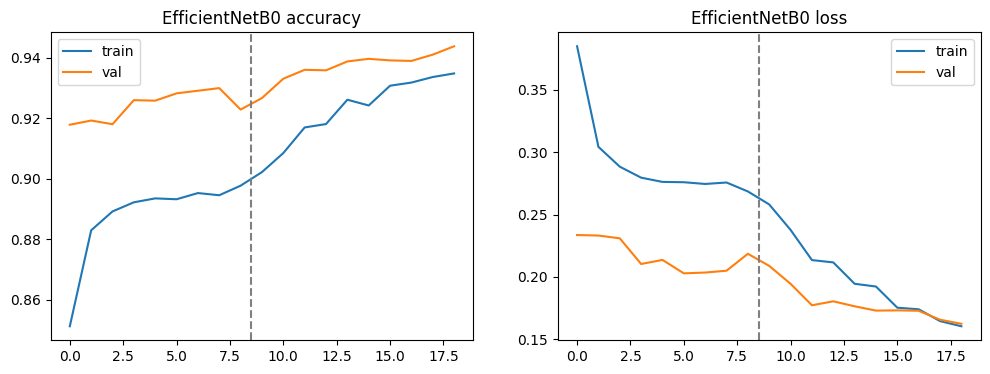

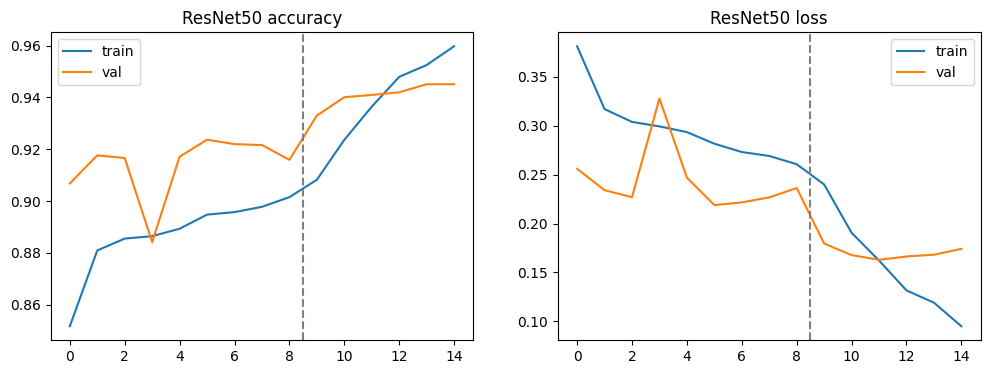

In [28]:
def plot_history(h1, h2, title):
    acc = h1.history["accuracy"] + h2.history["accuracy"]
    val_acc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
    loss = h1.history["loss"] + h2.history["loss"]
    val_loss = h1.history["val_loss"] + h2.history["val_loss"]

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(acc, label="train")
    plt.plot(val_acc, label="val")
    plt.axvline(len(h1.history["loss"]) - 0.5, color="gray", linestyle="--")
    plt.title(title + " accuracy")
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(loss, label="train")
    plt.plot(val_loss, label="val")
    plt.axvline(len(h1.history["loss"]) - 0.5, color="gray", linestyle="--")
    plt.title(title + " loss")
    plt.legend()
    plt.show()

plot_history(eff_hist1, eff_hist2, "EfficientNetB0")
plot_history(res_hist1, res_hist2, "ResNet50")

## Test results

Accuracy alone is not enough here because of the imbalance, so we also look at F1 for each class.

In [29]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])

eff_pred = eff_model.predict(eff_test).argmax(axis=1)
res_pred = res_model.predict(res_test).argmax(axis=1)

print("EfficientNetB0")
print(classification_report(y_true, eff_pred, target_names=CLASS_NAMES, digits=3))
print("ResNet50")
print(classification_report(y_true, res_pred, target_names=CLASS_NAMES, digits=3))

183/184 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step

E0000 00:00:1795551065.622248     167 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795551065.781853     167 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795551066.912846     167 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795551067.089036     167 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


184/184 ━━━━━━━━━━━━━━━━━━━━ 21s 81ms/step
184/184 ━━━━━━━━━━━━━━━━━━━━ 28s 133ms/step
EfficientNetB0
              precision    recall  f1-score   support

    barriers      0.950     0.919     0.934      1204
   sidewalks      0.817     0.887     0.851       974
     pothole      0.962     0.950     0.956      3693

    accuracy                          0.933      5871
   macro avg      0.910     0.919     0.914      5871
weighted avg      0.935     0.933     0.934      5871

ResNet50
              precision    recall  f1-score   support

    barriers      0.948     0.921     0.934      1204
   sidewalks      0.885     0.839     0.861       974
     pothole      0.949     0.971     0.960      3693

    accuracy                          0.939      5871
   macro avg      0.927     0.910     0.919      5871
weighted avg      0.938     0.939     0.939      5871



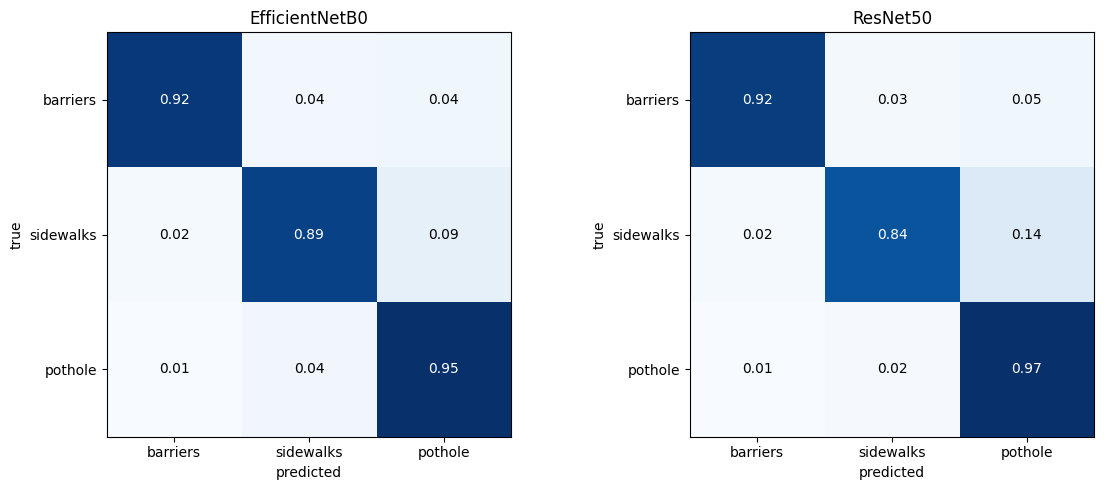

In [30]:
plt.figure(figsize=(12, 5))
for i, (name, pred) in enumerate([("EfficientNetB0", eff_pred), ("ResNet50", res_pred)]):
    cm = confusion_matrix(y_true, pred, normalize="true")
    plt.subplot(1, 2, i + 1)
    plt.imshow(cm, cmap="Blues")
    for r in range(3):
        for c in range(3):
            plt.text(c, r, f"{cm[r, c]:.2f}", ha="center", va="center",
                     color="white" if cm[r, c] > 0.5 else "black")
    plt.xticks(range(3), CLASS_NAMES)
    plt.yticks(range(3), CLASS_NAMES)
    plt.xlabel("predicted")
    plt.ylabel("true")
    plt.title(name)
plt.tight_layout()
plt.show()

## Comparison

In [31]:
results = pd.DataFrame({
    "EfficientNetB0": [(eff_pred == y_true).mean(), f1_score(y_true, eff_pred, average="macro"),
                       eff_model.count_params() / 1e6, eff_time / 60],
    "ResNet50": [(res_pred == y_true).mean(), f1_score(y_true, res_pred, average="macro"),
                 res_model.count_params() / 1e6, res_time / 60],
}, index=["accuracy", "macro F1", "params (M)", "train time (min)"])

results.round(3)

,EfficientNetB0,ResNet50
accuracy,0.933,0.939
macro F1,0.914,0.919
params (M),4.053,23.594
train time (min),68.916,59.455


Images where both models are wrong:

209 images


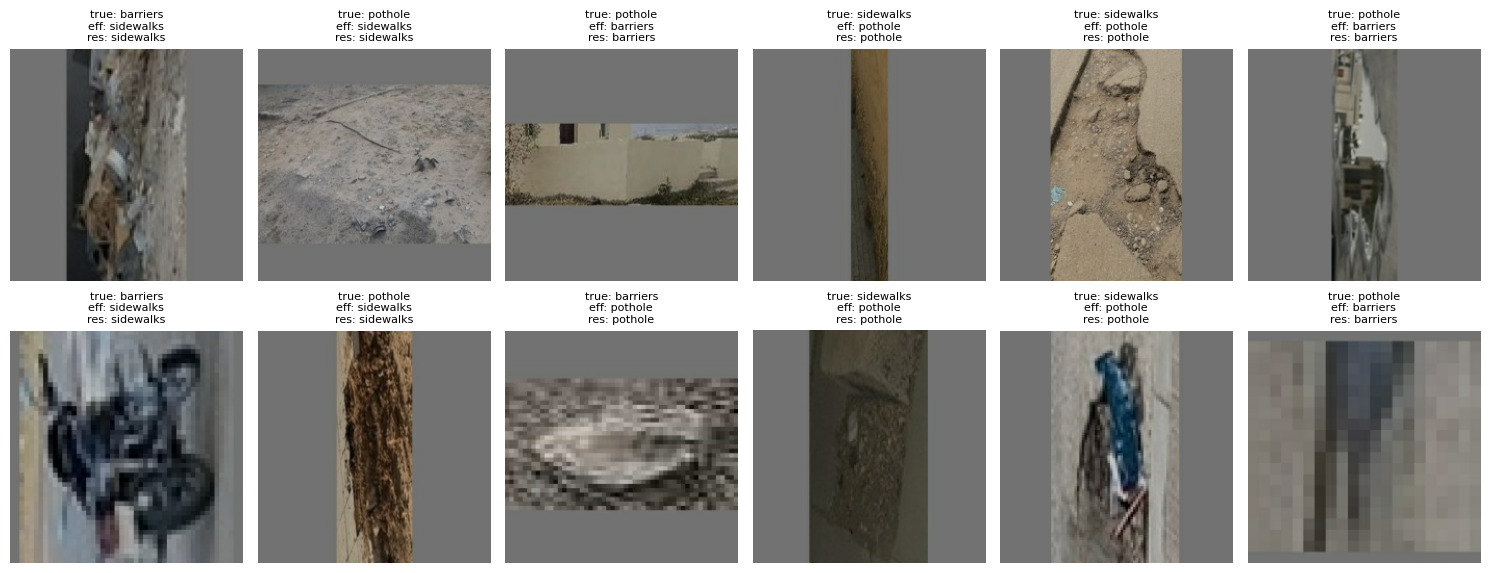

In [32]:
test_images = np.concatenate([x.numpy() for x, _ in test_ds])
wrong = np.where((eff_pred != y_true) & (res_pred != y_true))[0]
print(len(wrong), "images")

plt.figure(figsize=(15, 6))
for i, idx in enumerate(np.random.choice(wrong, min(12, len(wrong)), replace=False)):
    plt.subplot(2, 6, i + 1)
    plt.imshow(test_images[idx].astype("uint8"))
    plt.title(f"true: {CLASS_NAMES[y_true[idx]]}\neff: {CLASS_NAMES[eff_pred[idx]]}\nres: {CLASS_NAMES[res_pred[idx]]}",
              fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()